In [11]:
%load_ext pyspecdata.ipy
import pyspecdata as psd
import pandas as pd

The pyspecdata.ipy extension is already loaded. To reload it, use:
  %reload_ext pyspecdata.ipy


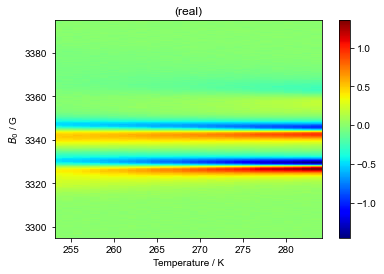

In [12]:
d = psd.find_file("240510_TS_C10_W3S2_run4", exp_type='francklab_esr/Romana')
d = d['harmonic',0]
d.pcolor()

In [15]:
d.get_prop('MWFQ')/1e9

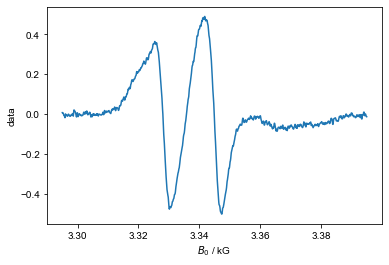

In [3]:
d['Temperature',0]

In [4]:
df = pd.DataFrame(data=d['Temperature',0].data,
          index=d.getaxis('$B_0$'),
          columns=['signal'])
df.index.name = 'Field [G]'
df.to_csv('low_T_slice_240812.csv')

In [9]:
with open('low_T_slice_240812.ascii','w') as fp:
    for j in range(d.shape['$B_0$']):
        fp.write(f"{d['$B_0$'][j]:-15f} {d['Temperature',0].data[j]:-15f}\n")

In [ ]:
with open('low_T_slice_240812.Settings','rb') as fp:
    data = fp.read()
poslist = []
poslist_endheader = []
for stringtype in ['Settings','Tensor', 'Parameter']:
    for idx in range(4):
        headerstring = f'{stringtype} Set {idx}'
        pos = (data.find(headerstring.encode('ascii')))
        poslist.append(pos)
        poslist_endheader.append(pos+len(headerstring))
poslist = [0] + poslist # figured out the first 4 is the number 4, then block, then label
poslist_endheader = [4] + poslist_endheader
poslist.sort()
poslist_endheader.sort()
print(poslist)
print(poslist_endheader)
print(frombuffer(data[:4],'>i4'))
print(frombuffer(data[4:64],'>i4'))

In [118]:
test_string = data[300:771] # should be tensors
print(frombuffer(test_string[192:300],'>f4'))
for offset in range(4):
    round_len = len(test_string)-offset
    round_len -= round_len % 4
    result = frombuffer(test_string[offset:offset+round_len],'>f4')
    print(all(logical_and(result>0, result<1e5)))

[ 1.44999993e+00 -1.58818684e-23  1.87500000e+00  0.00000000e+00
  1.44999993e+00 -1.58818684e-23  1.87500000e+00  0.00000000e+00
  1.44999993e+00 -1.58818684e-23  1.87500000e+00  0.00000000e+00
  1.87500000e+00  0.00000000e+00  5.60519386e-45  2.35098870e-38
  5.31898499e+00  0.00000000e+00  3.39062500e+00  0.00000000e+00
  5.60519386e-45  4.20389539e-45  2.35624981e+00 -1.07374184e+08
  2.37500000e+00  0.00000000e+00  3.04296875e+00]
False
False
False
False


In [43]:
# look at the first block of binary
for offset in range(8):
    for thisformat in ['<f4','>f4','<i4','>i4','<f8','>f8']:
        print(frombuffer(data[j+offset:j+56+offset],thisformat))

[ 1.8340194e-41 -6.9142914e-10 -1.1993041e-06  3.0488704e+03
  1.6484157e-09 -6.9204797e-10 -1.1993041e-06 -6.9323286e-10
 -1.1993041e-06 -6.9323286e-10 -1.1993041e-06 -6.9323286e-10
 -1.1993041e-06 -6.9323286e-10]
[ 1.5161890e-19  1.4000205e-39 -3.1696354e+04 -5.4640832e+27
  9.2736723e+34 -1.4347783e-31 -3.1696354e+04 -5.4641464e+27
 -3.1696354e+04 -5.4641464e+27 -3.1696354e+04 -5.4641464e+27
 -3.1696354e+04 -5.4641464e+27]
[      13088 -1338110208 -1247742010  1161727469   820153977 -1338099060
 -1247742010 -1338077715 -1247742010 -1338077715 -1247742010 -1338077715
 -1247742010 -1338077715]
[  540213248      999088  -956849995  -309510587  2039407152 -1942339920
  -956849995  -309510480  -956849995  -309510480  -956849995  -309510480
  -956849995  -309510480]
[-2.59591082e-76  3.69380132e+25 -2.61060163e-76 -2.63873021e-76
 -2.63873021e-76 -2.63873021e-76 -2.63873021e-76]
[ 1.41708474e-153 -7.66765169e+033  3.42163190e+277 -7.66765169e+033
 -7.66765169e+033 -7.66765169e+033 -7.6676

In [37]:
datalen = diff(poslist)-len(headerstring)
assert(all(datalen==datalen[0]))
datalen = datalen[0]
print("check datalen",datalen,datalen%8,datalen%4)
startpos = array(poslist)+len(headerstring)
for j in startpos:
    print(f"\n\nstarting pos {j}")
    for offset in range(8):
        for thisformat in ['<f4','>f4','<i4','>i4','<f8','>f8']:
            print(frombuffer(data[j+offset:j+56+offset],thisformat))

64
138
212
286
check datalen 62 6 2


starting pos 76
[1.7264e-41 7.1746e-43 0.0000e+00 1.0762e-42 0.0000e+00 0.0000e+00
 0.0000e+00 0.0000e+00 5.3810e-42 1.7937e-42 5.0223e-42 3.9461e-42
 2.1524e-42 7.1746e-43]
[1.490778e-19 1.836710e-40 0.000000e+00 2.755065e-40 0.000000e+00
 0.000000e+00 0.000000e+00 0.000000e+00 1.377532e-39 4.591775e-40
 1.285697e-39 1.010190e-39 5.510130e-40 1.836710e-40]
[12320   512     0   768     0     0     0     0  3840  1280  3584  2816
  1536   512]
[540016640    131072         0    196608         0         0         0
         0    983040    327680    917504    720896    393216    131072]
[1.08646185e-311 1.62969277e-311 0.00000000e+000 0.00000000e+000
 2.71615461e-311 5.97554015e-311 1.08646185e-311]
[1.19333452e-153 9.71372585e-319 0.00000000e+000 0.00000000e+000
 2.08600674e-308 1.94693963e-308 8.34402697e-309]
[6.7e-44 2.8e-45 0.0e+00 4.2e-45 0.0e+00 0.0e+00 0.0e+00 0.0e+00 2.1e-44
 7.0e-45 2.0e-44 1.5e-44 8.4e-45 2.8e-45]
[4.6566129e-10 9.4039548e-3

In [7]:
# 1D data
d = psd.find_file("240808_100mM_TS_W30_C8", exp_type='francklab_esr/Romana') # HE:240808 DATA:100 mM TEMPO-SO4 in Isooctane w0=30
d = d['harmonic',0]

In [8]:
with open('240808_100mM_TS_W30_C8.ascii','w') as fp:
    for j in range(d.shape['$B_0$']):
        fp.write(f"{d['$B_0$'][j]:-15f} {d.data[j]:-15f}\n")

In [9]:
with open('240808_100mM_TS_W30_C8.ascii','r') as fp:
    print(fp.read())

    3405.000000        0.112160
    3405.043950        0.113121
    3405.087899        0.113042
    3405.131849        0.112629
    3405.175798        0.112012
    3405.219748        0.111552
    3405.263698        0.110191
    3405.307647        0.108113
    3405.351597        0.109580
    3405.395546        0.113157
    3405.439496        0.114095
    3405.483446        0.113316
    3405.527395        0.112783
    3405.571345        0.111592
    3405.615294        0.111113
    3405.659244        0.111585
    3405.703194        0.110678
    3405.747143        0.110738
    3405.791093        0.111964
    3405.835042        0.111234
    3405.878992        0.109985
    3405.922942        0.110659
    3405.966891        0.112372
    3406.010841        0.112026
    3406.054791        0.110815
    3406.098740        0.112118
    3406.142690        0.114224
    3406.186639        0.115321
    3406.230589        0.116288
    3406.274539        0.116341
    3406.318488        0.115122
    3406